# Lab 7: Go-to-goal

**Diyorbek Shokirov, ID 240046**

The robot drives my digits **46** through 11 waypoints with the go-to-goal controller. The same block program runs
in the 2D simulator (`go_to_goal_sim.qrs`) and on the real robot (`go_to_goal_real.qrs`); only $r$, $B$,
$V_{100}$ and the file name are different. Every loop it writes one line `x,y,time` (cm, cm, ms).

Every loop the program computes (lengths in cm, $\theta$ = heading from odometry):

$$\rho = \sqrt{(x_g-x)^2 + (y_g-y)^2}, \qquad e = \text{wrap}\big(\text{atan2}(y_g-y,\ x_g-x) - \theta\big)$$

$$v = \min\big(\max(K_v\rho,\ v_{min}),\ v_{max}\big)\cdot\max\big(1 - |e|/e_{drive},\ 0\big), \qquad
\omega = \text{clamp}(K_\theta e,\ \pm\omega_{max})$$

$$v_{R,L} = v \pm \omega\frac{B}{2}, \qquad \text{power}_{R,L} = 100\,\frac{v_{R,L}}{V_{100}}$$

When $\rho < \varepsilon$ it goes to the next waypoint. I added two things to the lecture version: $v_{min}$, so the
robot does not get stuck in the motor dead zone near a waypoint, and the last factor in $v$, so at a corner it
first turns on the spot and only then drives (sharper corners).

| | $K_v$ | $v_{min}$ | $v_{max}$ | $K_\theta$ | $\omega_{max}$ | $e_{drive}$ | $\varepsilon$ |
|---|---|---|---|---|---|---|---|
| both programs | 1.5 1/s | 10 cm/s | 15 cm/s | 4 1/s | 1.5 rad/s | 0.3 rad | 2 cm |

| | $r$ | $B$ | $V_{100}$ (wheel speed at 100 %) |
|---|---|---|---|
| 2D model | 2.8 cm | 15.4 cm | 27 cm/s (measured in the simulator) |
| real robot | 3.75 cm | 19.4 cm | 60 cm/s (from Lab 5) |

The real log is from my second run on the robot; the first one stopped after 19 s on the way to the 6.

In [1]:
import os
import numpy as np                  # arrays and maths
import matplotlib.pyplot as plt     # plots

if not os.path.exists('odometry_data_sim.txt'):   # only in Colab: upload both txt files first
    from google.colab import files
    uploaded = files.upload()

# the waypoints of "46" in cm, same order as in the TRIK program; point 0 is the start
wp = np.array([[0, 0], [0, -20], [20, -20], [20, 0], [20, -40],          # the 4
               [40, -40],                                                 # gap to the 6
               [40, -20], [60, -20], [60, -40], [40, -40], [40, 0], [60, 0]])   # the 6

# every line of a log is x, y, time; unpack=True gives three separate arrays
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)   # simulator, cm
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)   # real robot, cm

for name, t in (('simulator', t_s), ('real robot', t_r)):
    print(f'{name}: {len(t)} lines, {(t[-1] - t[0]) / 1000:.1f} s, one loop = {np.diff(t).mean():.0f} ms')

simulator: 3146 lines, 31.9 s, one loop = 10 ms
real robot: 387 lines, 44.9 s, one loop = 116 ms


## 1. Planned path, simulator and real robot

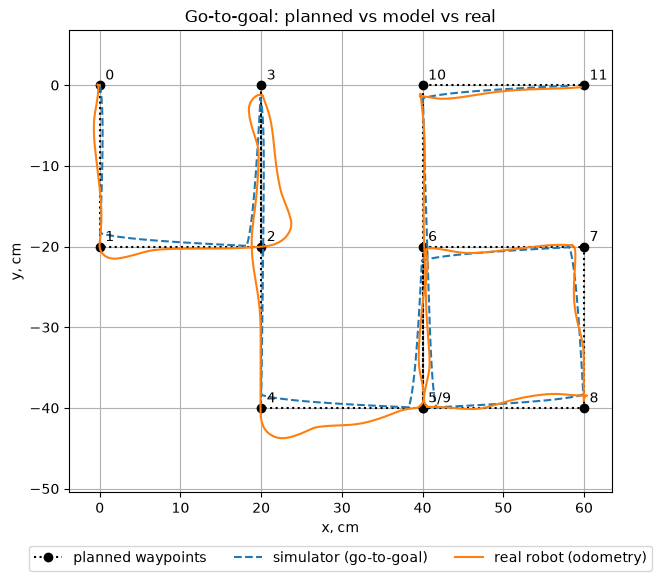

In [2]:
plt.figure(figsize=(7, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')                 # the plan
plt.plot(x_s, y_s, '--', label='simulator (go-to-goal)')                       # dashed = simulator
plt.plot(x_r, y_r,       label='real robot (odometry)')                        # solid = real robot odometry
for px, py in np.unique(wp, axis=0):                       # number the waypoints; point 5 = point 9 -> "5/9"
    nums = [str(i) for i, p in enumerate(wp) if p[0] == px and p[1] == py]
    plt.annotate('/'.join(nums), (px, py), textcoords='offset points', xytext=(4, 4))
plt.axis('equal'); plt.grid(True)                                              # equal axes: the 46 is not stretched
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.xlabel('x, cm'); plt.ylabel('y, cm')                                       # x = start direction, y = left
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

Both runs draw the 46. In the simulator the robot turns on the spot at every corner and then drives straight; it
switches 2 cm before each corner (ε), so the corners are cut a little. On the real robot the corners are sharp
too, but after some turns the path swings to the side before it settles: 3.7 cm to the right after corner 2 and
3.8 cm below the line after corner 4.

## 2. Waypoint miss, path error and run time

Miss = how close the path came to each waypoint (function from the lab README). Path error = for every logged
point, the distance to the planned lines of the 46.

In [3]:
def waypoint_miss(x, y, wp):            # closest distance of the whole path to each waypoint
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

# the planned lines as many small points, one every 0.5 cm
plan = np.vstack([np.linspace(a, b, int(np.hypot(*(b - a)) / 0.5) + 1) for a, b in zip(wp[:-1], wp[1:])])

def path_error(x, y):                    # distance from every logged point to the closest plan point
    return np.min(np.hypot(x[:, None] - plan[:, 0], y[:, None] - plan[:, 1]), axis=1)

miss_s, miss_r = waypoint_miss(x_s, y_s, wp), waypoint_miss(x_r, y_r, wp)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i:2d} ({wp[i, 0]:2d}, {wp[i, 1]:3d}): sim {ms:5.1f} cm | real {mr:5.1f} cm')

for name, x, y, t in (('sim ', x_s, y_s, t_s), ('real', x_r, y_r, t_r)):
    pe = path_error(x, y)
    print(f'{name}: run time {(t[-1] - t[0]) / 1000:4.1f} s, path error max {pe.max():4.1f} cm, mean {pe.mean():.1f} cm')

Waypoint  0 ( 0,   0): sim   0.0 cm | real   0.0 cm
Waypoint  1 ( 0, -20): sim   1.6 cm | real   0.0 cm
Waypoint  2 (20, -20): sim   0.3 cm | real   0.3 cm
Waypoint  3 (20,   0): sim   1.6 cm | real   1.2 cm
Waypoint  4 (20, -40): sim   1.6 cm | real   0.2 cm
Waypoint  5 (40, -40): sim   1.7 cm | real   0.4 cm
Waypoint  6 (40, -20): sim   0.6 cm | real   0.6 cm
Waypoint  7 (60, -20): sim   1.8 cm | real   1.2 cm
Waypoint  8 (60, -40): sim   1.6 cm | real   0.9 cm
Waypoint  9 (40, -40): sim   1.7 cm | real   0.4 cm
Waypoint 10 (40,   0): sim   1.6 cm | real   1.1 cm
Waypoint 11 (60,   0): sim   1.8 cm | real   0.5 cm
sim : run time 31.9 s, path error max  1.5 cm, mean 0.4 cm
real: run time 44.9 s, path error max  3.8 cm, mean 0.7 cm


By odometry the simulator misses every corner by 1.6-1.8 cm, just under ε = 2 cm (2 and 6 are lower because the
path goes past them again later). The real robot gets closer, 0-1.2 cm, because one loop takes 116 ms instead of
10 ms, so it moves about 1 cm more before it sees ρ < ε. The path error is 1.5 cm at most in the simulator and
3.8 cm on the real robot. The real run takes 44.9 s against 31.9 s: on the floor the robot is slower than
V100 = 60 cm/s assumes (9 cm/s instead of 12 on the first stroke), because V100 is from Lab 5 with the wheels
in the air.

## 3. Measured end point

Before the run I marked the start point (middle between the wheels) and the start direction on the floor. After
the run I measured with a tape where that point stopped: x forward, y to the left.

In [4]:
x_meas, y_meas = 62, -9                  # tape [cm]

goal = wp[-1]                            # where the robot should stop
odo = np.array([x_r[-1], y_r[-1]])       # where it thinks it stopped (last line of the log)
tape = np.array([x_meas, y_meas])        # where it really stopped

# control error: did the robot go where it wanted?  localization error: does it know where it is?
print(f'last waypoint: ({goal[0]:5.1f}, {goal[1]:5.1f}) cm')
print(f'odometry end : ({odo[0]:5.1f}, {odo[1]:5.1f}) cm -> {np.hypot(*(odo - goal)):4.1f} cm from the waypoint (control error)')
print(f'tape         : ({tape[0]:5.1f}, {tape[1]:5.1f}) cm -> {np.hypot(*(tape - odo)):4.1f} cm from the odometry (localization error)')

last waypoint: ( 60.0,   0.0) cm
odometry end : ( 59.6,  -0.3) cm ->  0.5 cm from the waypoint (control error)
tape         : ( 62.0,  -9.0) cm ->  9.1 cm from the odometry (localization error)


## 4. Conclusions

In the simulator no corner is overshot: the robot turns on the spot while |e| > e_drive and then drives
straight, and every corner is cut by about 1.7 cm because of ε = 2 cm (my first try, with v times cos e, made
arcs of up to 3.6 cm after the corners). On the real robot the corners were not cut but overshot after the turn,
up to 3.8 cm to the side after corners 2 and 4: the robot starts driving at |e| = 0.3 rad and K_θ = 4 corrects
the heading late with a 116 ms loop and the motor delay, so a smaller e_drive or K_θ would probably make the
strokes straighter. By its own odometry the real robot still ends 0.5 cm from the last waypoint, so the
controller did its job and the real-vs-model gap is not a control problem. The tape shows it really stopped at
(62, -9) cm, 9.1 cm from where its odometry thinks, so the remaining gap is a localization problem (wheel slip,
not exact r or B) that no controller can fix, because it only trusts the odometry.